# Features available at forecast time

Reconstruct past-only price features and inspect the saved weekly model inputs.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

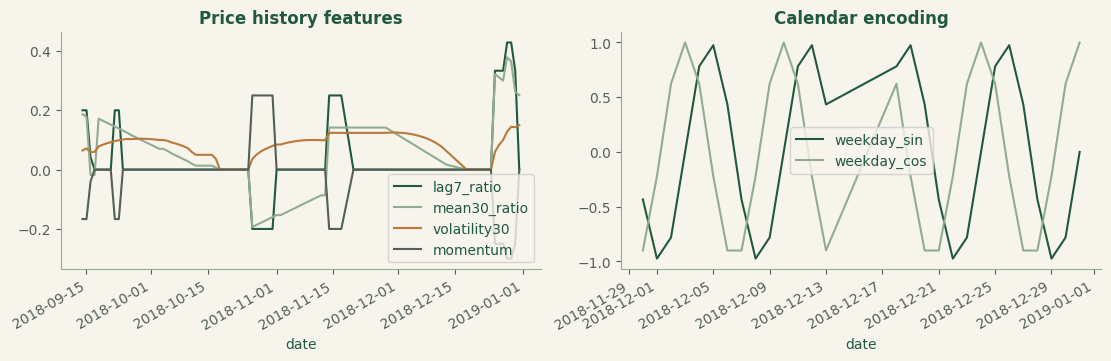

,lag2_ratio,lag7_ratio,mean7_ratio,mean30_ratio,volatility30,momentum,age_days,weekday_sin,weekday_cos,month_sin,month_cos
date,,,,,,,,,,,
2018-12-28,0.071,0.429,0.214,0.379,0.128,-0.30,3.0,-0.434,-0.901,-0.0,1.0
2018-12-29,0.000,0.429,0.153,0.364,0.144,-0.30,3.0,-0.975,-0.223,-0.0,1.0
2018-12-30,-0.067,0.333,0.029,0.262,0.143,-0.25,3.0,-0.782,0.623,-0.0,1.0
2018-12-31,0.000,0.000,-0.019,0.251,0.150,0.00,3.0,0.000,1.000,-0.0,1.0


In [2]:
from Code.daily.forecast import features, FEATURES
from Code.daily.policy import IST

history = development_market()
targets = history.date.drop_duplicates().iloc[-100:]
examples = []
for target in targets:
    issue = target.tz_localize(IST) + pd.Timedelta(hours=8)
    vector, eligibility, known = features(history, target, issue)
    if vector is not None:
        assert known.date.max() < target
        assert pd.to_datetime(known.available_at, utc=True, format="mixed").max() <= issue
        examples.append({"date": target, **dict(zip(FEATURES, vector))})
features_over_time = pd.DataFrame(examples).set_index("date")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
features_over_time[["lag7_ratio", "mean30_ratio", "volatility30", "momentum"]].plot(ax=axes[0], title="Price history features")
features_over_time[["weekday_sin", "weekday_cos"]].tail(28).plot(ax=axes[1], title="Calendar encoding")
plt.show()
display(features_over_time.tail(4).round(3))

In [3]:
from pyarrow.parquet import ParquetFile
schema = ParquetFile(DATA / "features/features_onion.parquet").schema.names
saved = pd.read_csv(PH8 / "model_features.csv")
display(saved.groupby("config").column.agg(["nunique", lambda x: ", ".join(x.head(5))]))
display(pd.Series([c for c in schema if "arrival" in c.lower()][:12], name="Archived arrivals feature fields").to_frame())

,nunique,<lambda_0>
config,,
no_weather,59,"year, month, quarter, day_of_week, month_sin"
weather,72,"year, month, quarter, day_of_week, month_sin"


,Archived arrivals feature fields
0,arrivals_tonnes
1,usable_arrivals
2,arrivals_extreme_level
3,arrivals_prev_obs
4,arrivals_prev_obs_days_ago
5,arrivals_change_prev_obs
6,arrivals_lag_1d
7,arrivals_lag_7d
8,arrivals_roll7d_mean
9,arrivals_roll7d_median


The historical archive uses assumed reporting availability for the demonstration. Operational observations use actual retrieval timestamps. Arrivals and weather were evaluated in separate historical work. The current daily price model does not consume these inputs.

**Takeaway** · Both observation date and availability time govern which prices enter a feature vector.

**Next** · Compare feature groups and selection evidence in Notebook 06.